In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
cleaned_data = pd.read_csv("../data/ChargingRecords_cleaned.csv")
print("Cleaned dataset loaded successfully!")

Cleaned dataset loaded successfully!


In [13]:
cleaned_data.describe(include='all')

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
count,72843.000000,72843.000000,72843.000000,72843,72843.000000,72843,72843,72843,72843,72843,72843,72843.000000,72843.000000
unique,NaN,NaN,NaN,14,NaN,366,43245,365,46710,65628,66745,NaN,NaN
top,NaN,NaN,NaN,public area,NaN,2022-08-10,18:28:39,2022-07-28,4:10:01,2022-05-16 15:10:00,2022-09-22 03:10:00,NaN,NaN
freq,NaN,NaN,NaN,14076,NaN,310,8,310,66,5,5,NaN,NaN
mean,338.084716,525.404143,0.627500,NaN,0.205195,NaN,NaN,NaN,NaN,NaN,NaN,151.183998,17.442667
std,553.916404,569.481406,0.483474,NaN,0.403847,NaN,NaN,NaN,NaN,NaN,NaN,146.420312,13.491446
min,0.000000,1.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,-29.000000,0.010000
25%,0.000000,107.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,40.000000,7.530000
50%,62.000000,301.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,112.000000,14.100000
75%,407.000000,738.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,202.000000,23.200000


Charging demand distribution

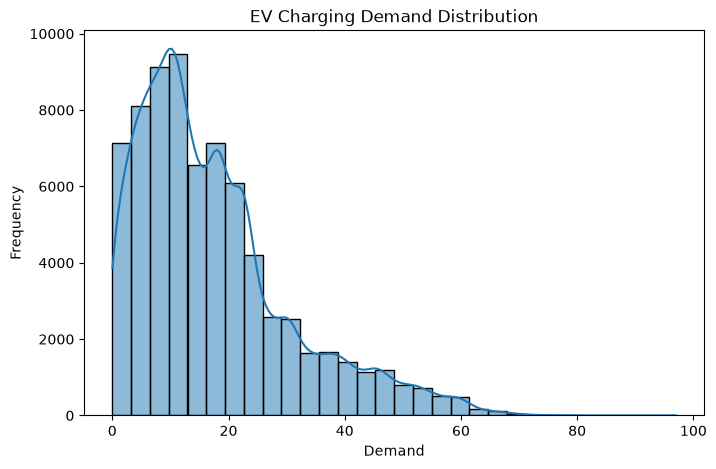

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(cleaned_data["Demand"], bins=30, kde=True)

plt.title("EV Charging Demand Distribution")
plt.xlabel("Demand")
plt.ylabel("Frequency")

plt.show()

Charger type analysis

Text(0, 0.5, 'Frequency')

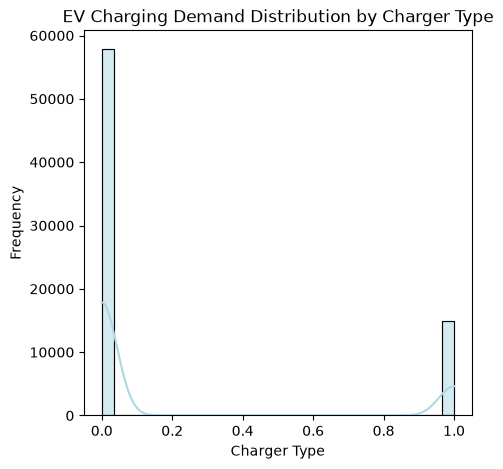

In [15]:
plt.figure(figsize=(5, 5))
sns.histplot(x=cleaned_data["ChargerType"], color='lightblue', kde=True,bins=30)
plt.title("EV Charging Demand Distribution by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Frequency")

Demand by charger type

Text(0, 0.5, 'Charger Type')

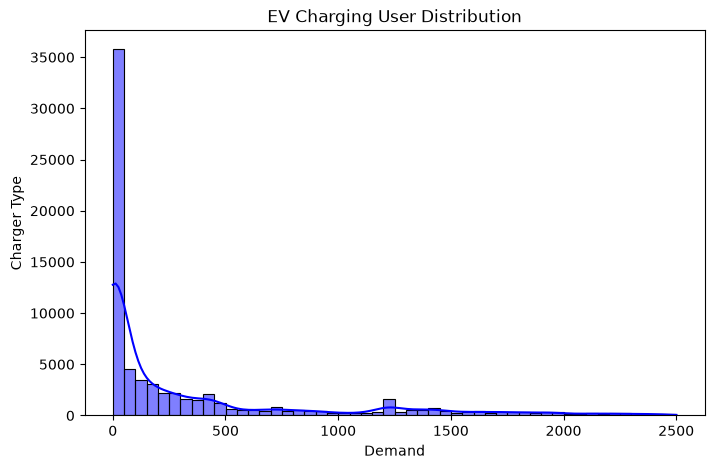

In [16]:
plt.figure(figsize=(8,5))
plt.title("EV Charging User Distribution")
sns.histplot(cleaned_data["UserID"], bins=50, kde=True,color='blue')
plt.xlabel("Demand")
plt.ylabel("Charger Type")

Charging activity by hour

In [17]:
cleaned_data["StartTime"] = pd.to_datetime(cleaned_data["StartTime"], errors="coerce")

C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_20732\1691639077.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cleaned_data["StartTime"] = pd.to_datetime(cleaned_data["StartTime"], errors="coerce")


In [18]:
cleaned_data["Hour"] = cleaned_data["StartTime"].dt.hour

visulazation 

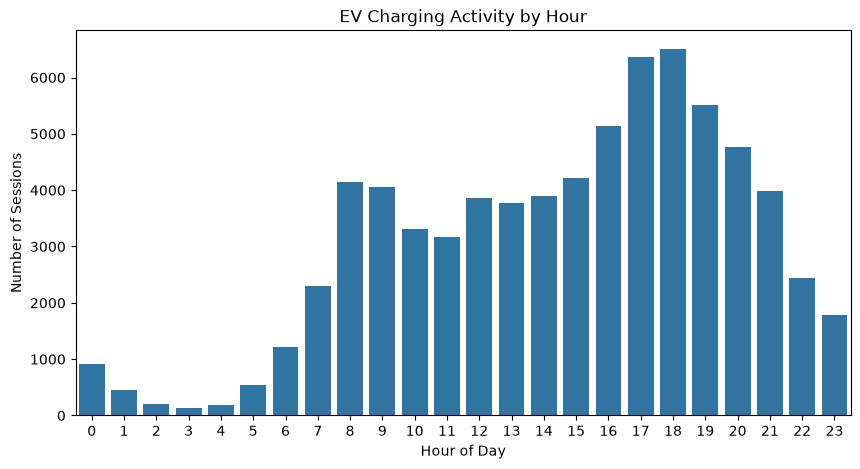

In [19]:
plt.figure(figsize=(10, 5))

sns.countplot(data=cleaned_data, x="Hour")

plt.title("EV Charging Activity by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Sessions")

plt.show()

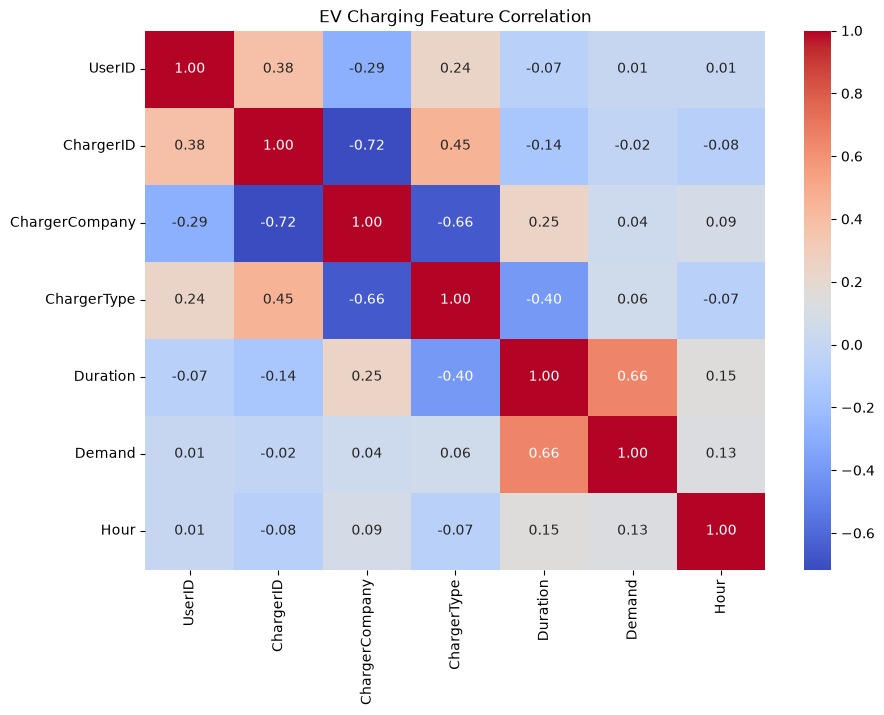

In [20]:
numeric_data = cleaned_data.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("EV Charging Feature Correlation")

plt.show()

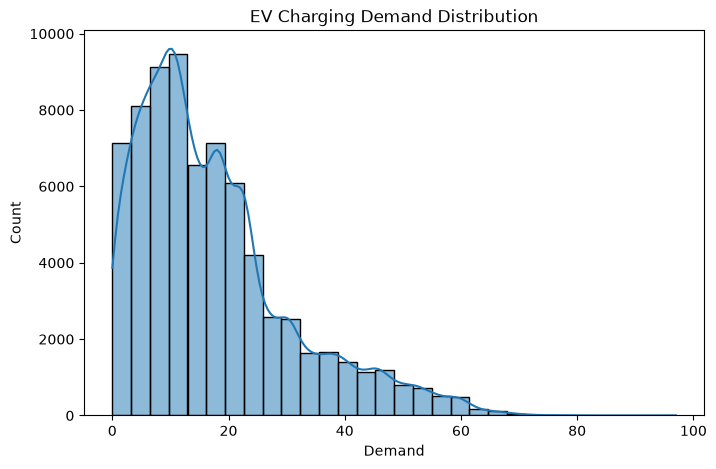

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(cleaned_data["Demand"], bins=30, kde=True)

plt.title("EV Charging Demand Distribution")

plt.savefig("../outputs/eda/demand_distribution.png",
            bbox_inches="tight")

plt.show()